## Statistics of a run

How far a run's numbers can be trusted, and what else describes it. Every statistic comes
with its interval, named for its method: the Sharpe's by the delta method over a long-run
variance that autocorrelation widens, the others by bootstrapping the returns in blocks or
the round trips. Then the probability that the Sharpe beats a benchmark and the track record
that would show it, the drawdowns, the round trips in other orders, alpha and beta, and two
runs set side by side. The crossing of two averages on hourly Bitcoin bars of 2024 and 2025.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import numpy
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 3.0.0, exchange-router 3.3.0


### The run

In [2]:
PATH = pathlib.Path("../bars/binance-spot-btcusdt-1h-2024-2025")

if PATH.exists():
    data = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        data = probatum.Data.from_router(router, exchange="binance", market="spot",
                                         interval="1h", symbols=["BTCUSDT"],
                                         start="2024-01-01", end="2025-12-31")
    data.save(path=PATH)

fast = probatum.ta.ema(data.close, length=24)
slow = probatum.ta.ema(data.close, length=24 * 10)

result = probatum.backtest(numpy.where(fast > slow, 1.0, 0.0), data=data,
                           venue="binance_spot", tolerance=0.05)

result.summary()

,run,buy_and_hold,low,high,level,method,why_none
total_return_pct,36.90,106.12,-52.66,290.04,0.95,"studentized stationary block bootstrap, blocks of 163.4 bars",
cagr_pct,16.98,43.50,-31.16,97.32,0.95,"studentized stationary block bootstrap, blocks of 163.4 bars",
volatility_pct,33.05,48.68,29.46,37.18,0.95,"studentized stationary block bootstrap, blocks of 163.4 bars",
sharpe,0.64,0.99,-0.75,2.03,0.95,"delta method, Newey-West lag 10, floored at lag zero",
max_drawdown_pct,30.40,34.76,20.48,62.68,0.95,"middle of resampled histories, stationary block bootstrap, blocks of 163.4 bars",
exposure_pct,53.83,,,,,,
num_trades,62,,,,,,
win_rate,0.29,,0.18,0.40,0.95,percentile bootstrap of round trips,
profit_factor,1.23,,0.51,3.02,0.95,BCa bootstrap of round trips,
costs,"2,105",,,,,,


### Intervals and their methods

Each interval records how it was made: the long-run variance's lag and whether its floor
bound for the Sharpe, the mean block length for a bootstrap of the returns, and the round
trips' count for one of them.

In [3]:
intervals = [result.stats.interval("sharpe"),
             probatum.stats.bootstrap(result, statistic="cagr_pct"),
             probatum.stats.bootstrap(result, statistic="max_drawdown_pct"),
             probatum.stats.bootstrap(result, statistic="win_rate"),
             probatum.stats.bootstrap(result, statistic="profit_factor")]

pandas.concat([interval.to_pandas() for interval in intervals])[
    ["estimate", "low", "high", "method", "kind", "count", "lag", "block"]].round(
    decimals=3)

,estimate,low,high,method,kind,count,lag,block
sharpe,0.640,-0.747,2.027,delta method,interval,17543,10.0,NaN
cagr_pct,16.981,-31.162,97.319,studentized stationary block bootstrap,interval,17543,NaN,163.445
max_drawdown_pct,30.402,20.477,62.683,stationary block bootstrap,range,17543,NaN,163.445
win_rate,0.290,0.177,0.403,percentile bootstrap of round trips,interval,62,NaN,NaN
profit_factor,1.227,0.508,3.022,BCa bootstrap of round trips,interval,62,NaN,NaN


### Against a benchmark Sharpe

The probability that the annual Sharpe is above each benchmark, and the track record a
Sharpe this high would need to show it at 95%.

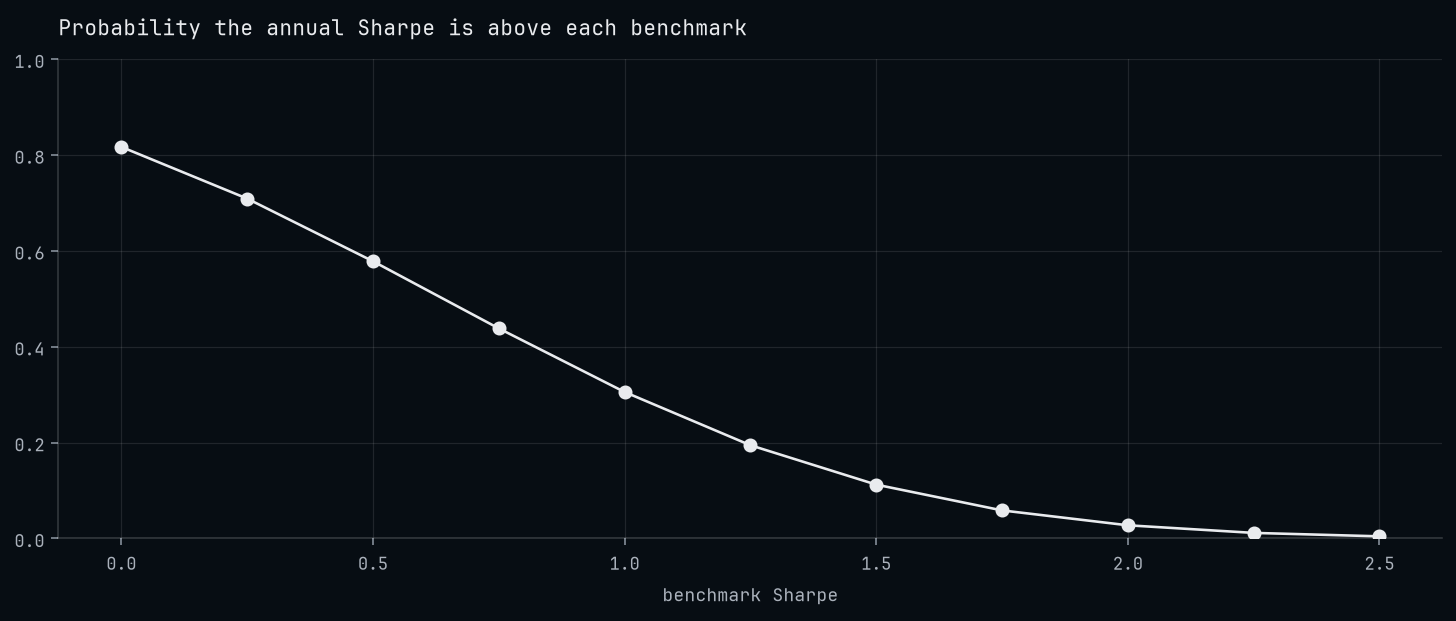

,observations,years,series_years,sharpe,confidence,benchmark,lag,floored,count
TrackRecord,1.213399e+06,138.51591,2.002626,0.640005,0.95,0.5,10,True,17543


In [4]:
benchmarks = numpy.arange(start=0.0, stop=2.51, step=0.25)
chances    = [probatum.stats.probabilistic_sharpe(result, benchmark=b).value
              for b in benchmarks]

axes = pandas.Series(chances, index=benchmarks).plot(
    marker="o", title="Probability the annual Sharpe is above each benchmark",
    xlabel="benchmark Sharpe")
axes.set_ylim(bottom=0.0, top=1.0)
matplotlib.pyplot.show()

probatum.stats.min_track_record_length(result, benchmark=0.5)

### Drawdowns

The five deepest, and how long the run spent under its peaks.

In [5]:
print(probatum.stats.time_under_water(result))

probatum.stats.drawdown_table(result, top=5).to_pandas()[
    ["peak_time", "trough_time", "recovered_time", "depth_pct", "bars_under"]].round(
    decimals=2)

            longest        mean  episodes     share  longest_days  mean_days
UnderWater     9698  287.383333        60  0.979536    404.083333  11.974306


,peak_time,trough_time,recovered_time,depth_pct,bars_under
0,2024-11-22 21:00:00+00:00,2025-12-31 19:00:00+00:00,NaT,30.40,9698
1,2024-03-14 06:00:00+00:00,2024-09-11 13:00:00+00:00,2024-11-10 22:00:00+00:00,24.25,5800
2,2024-01-11 14:00:00+00:00,2024-01-27 08:00:00+00:00,2024-02-11 03:00:00+00:00,13.59,733
3,2024-03-05 14:00:00+00:00,2024-03-05 19:00:00+00:00,2024-03-08 19:00:00+00:00,10.62,77
4,2024-11-13 18:00:00+00:00,2024-11-14 23:00:00+00:00,2024-11-19 17:00:00+00:00,5.92,143


### The round trips in other orders

The drawdown at trade closes and the longest losing run, as the round trips closed, beside
2,000 other orders of the same trips, each compounded on the equity it opened on.

In [6]:
probatum.stats.trade_order(result, n=2_000, seed=7)

,drawdown,drawdown_low,drawdown_high,deeper,losing_run,losing_run_low,losing_run_high,count,n
Permutations,24.744152,22.557327,49.197688,0.923,9,6,16,62,2000


### Alpha and beta

The run's excess returns regressed on buying and holding, with Newey-West errors.

In [7]:
probatum.stats.alpha_beta(result)

,alpha,alpha_error,alpha_low,alpha_high,alpha_t,beta,beta_error,beta_low,beta_high,tracking_error,information_ratio,lag,level,count
AlphaBeta,-0.009464,0.173215,-0.348959,0.330031,-0.054637,0.460633,0.037912,0.386327,0.534938,0.357613,-0.750027,81,0.95,17543


### Two runs side by side

`compare` puts runs in rows, and with `reference` tests each one's Sharpe against that
run's on the same bars, by the delta method and by a studentized block bootstrap.

In [8]:
slower = probatum.backtest(numpy.where(probatum.ta.ema(data.close, length=24 * 3)
                                       > probatum.ta.ema(data.close, length=24 * 30),
                                       1.0, 0.0),
                           data=data, venue="binance_spot", tolerance=0.05)

statistics = ["total_return_pct", "sharpe", "max_drawdown_pct", "num_trades"]

probatum.compare({"24 over 240": result, "72 over 720": slower}, keys=statistics,
                 reference="24 over 240").to_pandas().set_index(keys="name")[
    ["sharpe_difference", "difference_low", "difference_high", "p_delta", "p_bootstrap"]
    + statistics].round(decimals=3)

,sharpe_difference,difference_low,difference_high,p_delta,p_bootstrap,total_return_pct,sharpe,max_drawdown_pct,num_trades
name,,,,,,,,,
24 over 240,NaN,NaN,NaN,NaN,NaN,36.901,0.640,30.402,62
72 over 720,0.426,-0.541,1.393,0.388,0.389,81.660,1.066,27.852,20
